In [ ]:
import numpy as np
from cycler import cycler
import matplotlib.pyplot as plt
import math
import os
import scipy
import pathlib
import os
from pathlib import Path
from music21 import scale

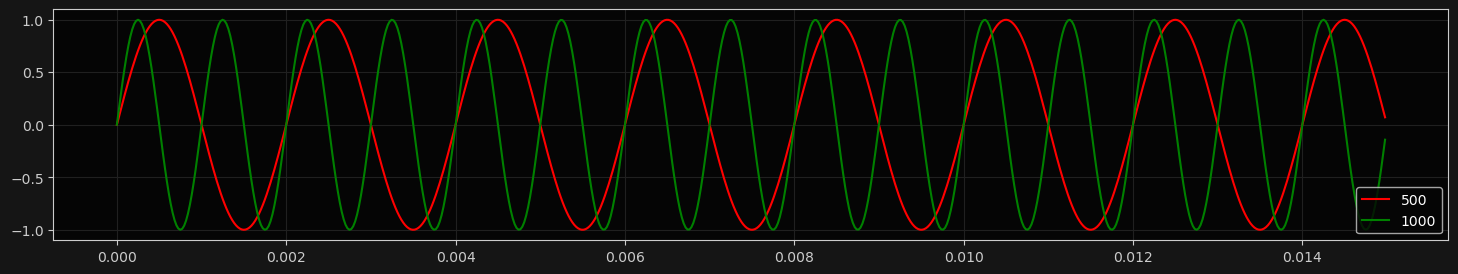

In [71]:
DUR = 15e-3
SR = 44100
FREQS = [500, 1000]
time = np.linspace(0, DUR, int(SR * DUR), endpoint=False)
sigs = {f: np.sin(2 * np.pi * f * time) for f in FREQS}

with plt.style.context(
    {
        "figure.facecolor": "#151515",
        "figure.edgecolor": "gray",
        "figure.figsize": (
            v / plt.rcParams["figure.dpi"] for v in [1800, 300]
        ),
        "axes.facecolor": "#050505",
        "axes.edgecolor": "#CCC",
        "text.color": "white",
        "grid.color": "#202020",
        "xtick.color": "#CCC",
        "ytick.color": "#CCC",
        "axes.prop_cycle": cycler(color=["red", "green", "blue"]),
    }
):
    for m, sig in sigs.items():
        plt.plot(time, sig, label=m)
    plt.legend(loc="lower right")
    plt.grid()
    plt.show()

### Plot sine wave

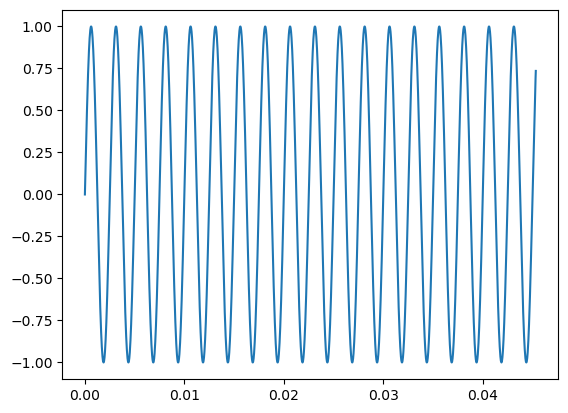

In [ ]:
DUR = 3
SR = 44100
FREQ = 400
time = np.linspace(0, DUR, int(SR) * DUR, endpoint=False)
sig = np.sin(2 * np.pi * FREQ * time)
plt.plot(time[0 : FREQ * 5], sig[0 : FREQ * 5])

### Write to file

In [ ]:
DUR = 3
SR = 44100
BASE = 400
FREQS_EQUAL = [BASE, BASE * 2 ** (4 / 12), BASE * 2 ** (7 / 12)]
FREQS_PERFECT = [BASE, BASE * 2 ** (4 / 3), BASE * (3 / 2)]
WAV_ABSPATH = (
    pathlib.Path(os.environ["ARTIFACTS_ABSPATH"])
    / "sine-400-minor-triad-equal-perfect.wav"
)

time = np.linspace(0, DUR, int(SR) * DUR, endpoint=False)
sig = []
for freq in FREQS:
    sig.append(np.sin(2 * np.pi * freq * time))

sig = np.sum(sig, axis=0)

plot_length = math.ceil(max(FREQS)) * 5
plt.plot(time[0:plot_length], sig[0:plot_length])
sig_max = np.max(np.abs(sig))
sig = sig / sig_max

pcm = np.int16(sig * (2**15 - 1))
scipy.io.wavfile.write(WAV_ABSPATH, SR, pcm)

[400, 503.96841995794927, 599.3228307506727]


In [ ]:
WAV_ABSPATH = pathlib.Path(os.environ["ARTIFACTS_ABSPATH"]) / "file.wav"
DUR = 2
SR = 44100
BASE = 400
FREQS = {
    "equal": [BASE, BASE * 2 ** (4 / 12), BASE * 2 ** (7 / 12)],
    "perfect": [BASE, BASE * (5 / 4), BASE * (3 / 2)],
}


def create_sig(freqs: list[int], duration: int):
    time = np.linspace(
        0,
        duration,
        int(SR) * duration,
        endpoint=False,
    )
    sig = []
    for freq in freqs:
        sig.append(scipy.signal.sawtooth(2 * np.pi * freq * time))
    sig = np.sum(sig, axis=0)
    sig_max = np.max(np.abs(sig))
    sig = sig / sig_max
    return sig


sigs = []
for i in range(4):
    for c in FREQS.values():
        sigs.append(create_sig(c, DUR))

sig = np.concatenate(sigs)

pcm = np.int16(sig * (2**15 - 1))
scipy.io.wavfile.write(WAV_ABSPATH, SR, pcm)